In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import AgglomerativeClustering
 
# Sample data: [Annual Spend ($1000s), Purchase Frequency (per year)]
X = np.array([
    [12, 2], [14, 3], [11, 2.5],   # low spend, low frequency
    [9, 18], [10, 20], [8, 17],    # low spend, high frequency
    [55, 3], [60, 4], [58, 2],     # high spend, low frequency
    [52, 19], [57, 21], [54, 20],  # high spend, high frequency
])


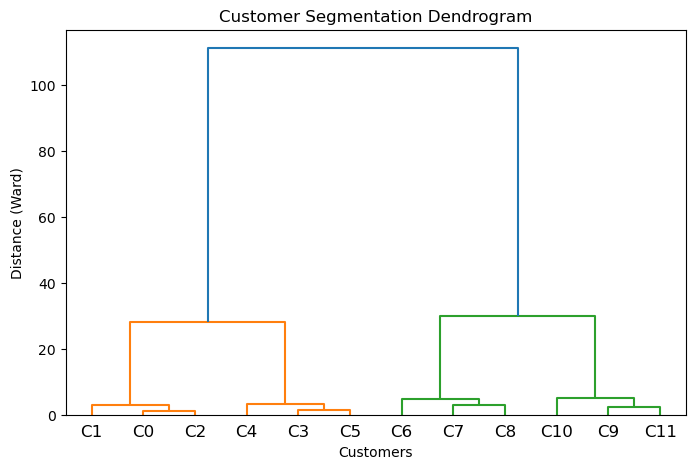

In [2]:
linked = linkage(X, method='ward')
 
plt.figure(figsize=(8, 5))
dendrogram(linked, labels=[f'C{i}' for i in range(len(X))])
plt.title('Customer Segmentation Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Distance (Ward)')
plt.show()


In [3]:
# Option A: cut by fixed number of clusters
model = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels = model.fit_predict(X)
print('Cluster labels:', labels)
 
# Option B: cut by a distance threshold using SciPy
labels_by_distance = fcluster(linked, t=30, criterion='distance')
print('Clusters from distance cut:', labels_by_distance)


Cluster labels: [3 3 3 1 1 1 2 2 2 0 0 0]
Clusters from distance cut: [1 1 1 1 1 1 2 2 2 3 3 3]


In [4]:
for c in np.unique(labels):
    pts = X[labels == c]
    print(f'Cluster {c}: mean spend={pts[:,0].mean():.1f}, '
          f'mean frequency={pts[:,1].mean():.1f}, size={len(pts)}')


Cluster 0: mean spend=54.3, mean frequency=20.0, size=3
Cluster 1: mean spend=9.0, mean frequency=18.3, size=3
Cluster 2: mean spend=57.7, mean frequency=3.0, size=3
Cluster 3: mean spend=12.3, mean frequency=2.5, size=3
